In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVC
import matplotlib.colors as mcolors
#202431006_Abyasa Rafa Asshadiq

In [ ]:
url_worldometer = 'https://www.worldometers.info/world-population/'
header = {"User-Agent": "Mozilla/5.0"}
req_worldometer = requests.get(url_worldometer, headers=header)
tabel_worldometer = pd.read_html(req_worldometer.text)
df_populasi = tabel_worldometer[0]

print("Data Dari Website Worldometer")
display(df_populasi.head())
#202431006_Abyasa Rafa Asshadiq

/tmp/ipykernel_2269/2871106508.py:4: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tabel_worldometer = pd.read_html(req_worldometer.text)


Data Dari Website Worldometer


,Year (July 1),Population,Yearly % Change,Yearly Change,Median Age,Fertility Rate,Density (P/KmÂ²)
0,2026,8300678395,0.84%,69065325,31.1,2.23,56
1,2025,8231613070,0.85%,69640498,30.9,2.24,55
2,2024,8161972572,0.87%,70237642,30.6,2.25,55
3,2023,8091734930,0.88%,70327738,30.4,2.25,54
4,2022,8021407192,0.84%,66958801,30.1,2.27,54


In [ ]:
url_scrape = 'https://www.scrapethissite.com/pages/forms/'
req_scrape = requests.get(url_scrape, headers=header)
tabel_scrape = pd.read_html(req_scrape.text)
df_hoki = tabel_scrape[0]

print("Data Dari Website Scrapper")
display(df_hoki.head())
#202431006_Abyasa Rafa Asshadiq

Data Dari Website Scrapper


/tmp/ipykernel_2269/4023989679.py:3: FutureWarning: Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.
  tabel_scrape = pd.read_html(req_scrape.text)


,Team Name,Year,Wins,Losses,OT Losses,Win %,Goals For (GF),Goals Against (GA),+ / -
0,Boston Bruins,1990,44,24,NaN,0.550,299,264,35
1,Buffalo Sabres,1990,31,30,NaN,0.388,292,278,14
2,Calgary Flames,1990,46,26,NaN,0.575,344,263,81
3,Chicago Blackhawks,1990,49,23,NaN,0.613,284,211,73
4,Detroit Red Wings,1990,34,38,NaN,0.425,273,298,-25


In [ ]:
df_csv = pd.read_csv('/content/Sleep_health_and_lifestyle_dataset.csv')

display(df_csv.head())

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,NaN
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,NaN
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [ ]:

df_kotor = pd.concat([df_csv, df_csv.iloc[[0,1]]], ignore_index=True)

print(f"Jumlah baris awal: {len(df_csv)}, setelah kotor: {len(df_kotor)}")
#202431006_Abyasa Rafa Asshadiq

Jumlah baris awal: 374, setelah kotor: 376


Text(0.5, 1.0, 'Peta Dta Kosong')

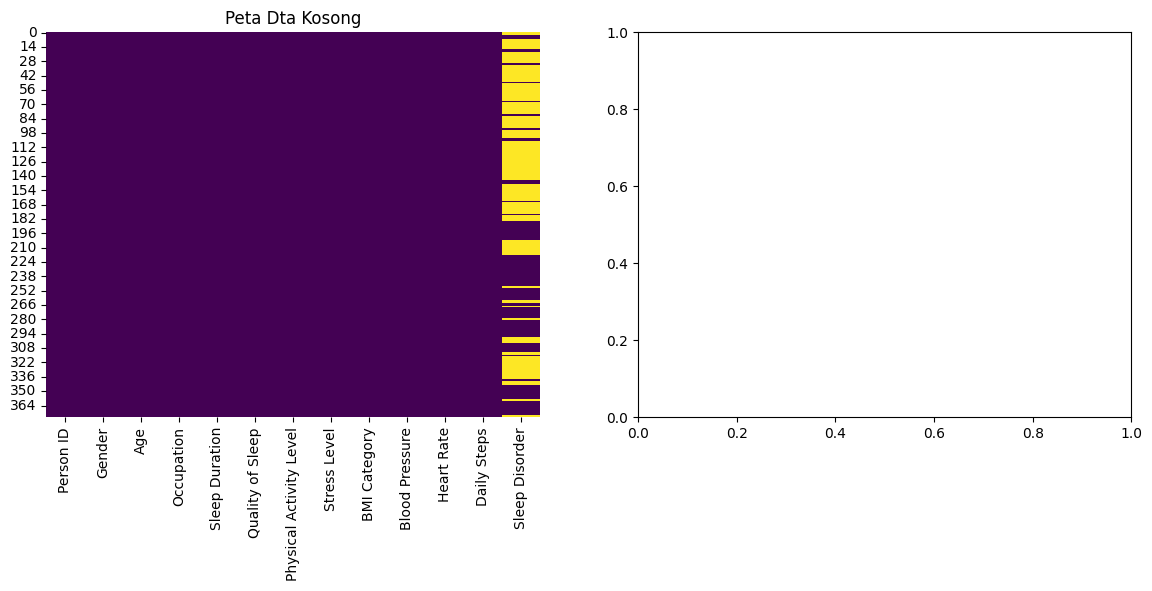

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(df_kotor.isnull(), cbar=False, cmap='viridis', ax=ax[0])
ax[0].set_title('Peta Dta Kosong')
#202431006_Abyasa Rafa Asshadiq

In [ ]:
sns.boxplot(x=df_kotor['Sleep Duration'], ax=ax[1], color='skyblue')
ax[1].set_title('Boxplot Durasi Tidur')

plt.tight_layout()
plt.show()
#202431006_Abyasa Rafa Asshadiq

<Figure size 640x480 with 0 Axes>

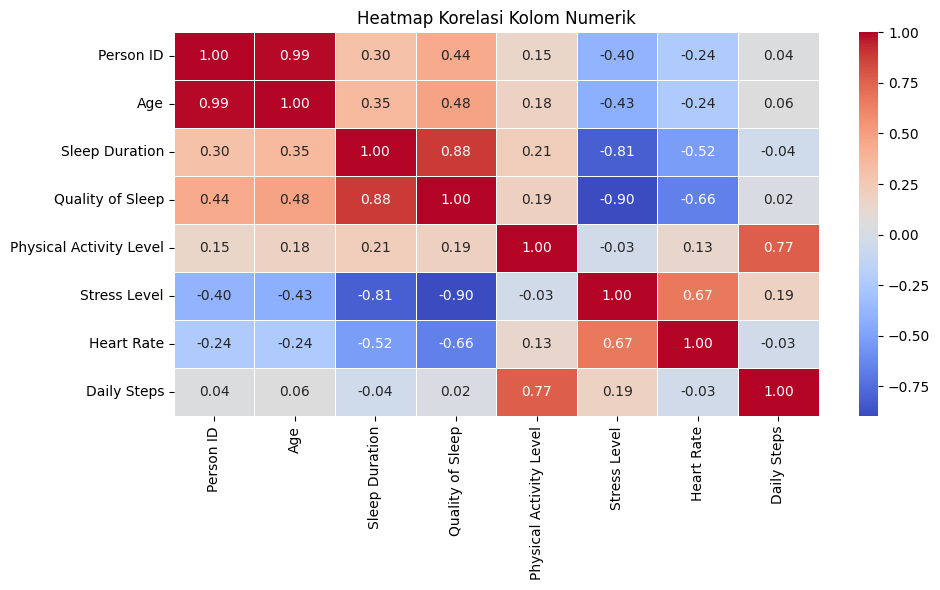

In [ ]:
kolom_numerik = df_kotor.select_dtypes(include=[np.number])

plt.figure(figsize=(10, 6))

sns.heatmap(
    kolom_numerik.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Heatmap Korelasi Kolom Numerik')
plt.tight_layout()
plt.show()
#202431006_Abyasa Rafa Asshadiq

In [ ]:
  diabetes = datasets. load_diabetes()
X_reg = diabetes.data[:, np.newaxis,2]
Y_reg = diabetes.target

iris = datasets.load_iris()
X_clf = iris.data[:, :2]
Y_clf = iris.target

print("Dataset Berhasil Dimuat")
#202431006_Abyasa Rafa Asshadiq

Dataset Berhasil Dimuat


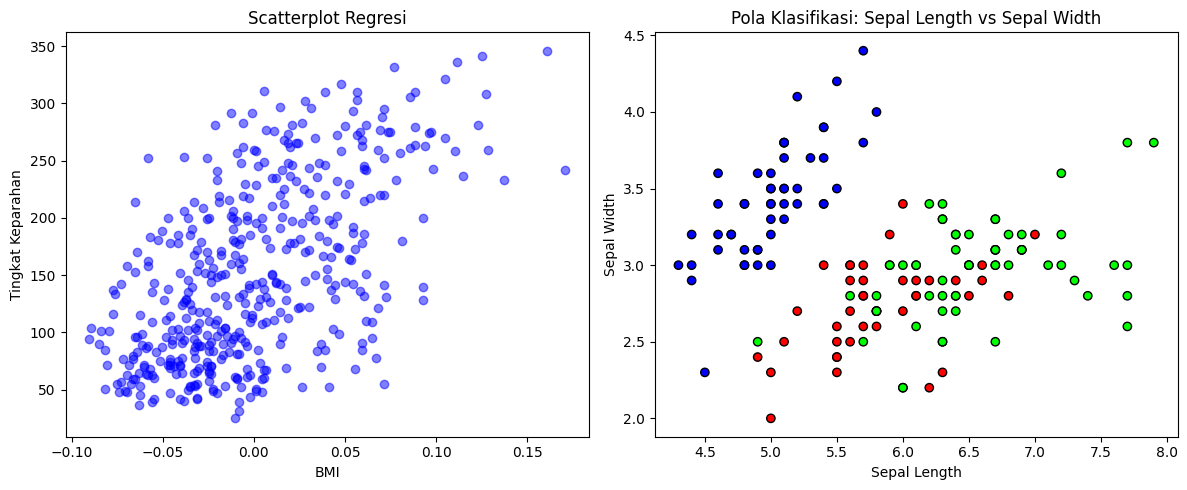

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(X_reg, Y_reg, color='blue', alpha=0.5)
ax[0].set_title('Scatterplot Regresi')
ax[0].set_xlabel('BMI')
ax[0].set_ylabel('Tingkat Keparahan')

scatter = ax[1].scatter(X_clf[:, 0], X_clf[:, 1], c=Y_clf, cmap='brg', edgecolor='k')
ax[1].set_title('Pola Klasifikasi: Sepal Length vs Sepal Width')
ax[1].set_xlabel('Sepal Length')
ax[1].set_ylabel('Sepal Width')

plt.tight_layout()
plt.show()
#202431006_Abyasa Rafa Asshadiq

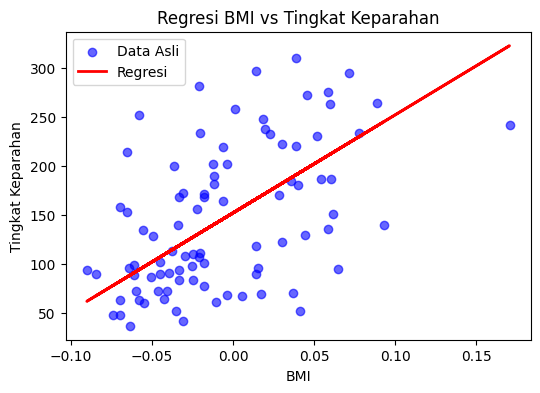

Tingkat Keparahan untuk BMI 0.00 adalah 154.25


In [ ]:
X_train_reg, X_test_reg, Y_train_reg, Y_test_reg = train_test_split(
    X_reg, Y_reg, test_size=0.2, random_state=42
)

model_reg = LinearRegression()
model_reg.fit(X_train_reg, Y_train_reg)

Y_pred_reg = model_reg.predict(X_test_reg)

plt.figure(figsize=(6, 4))
plt.scatter(X_test_reg, Y_test_reg, color='blue', alpha=0.6, label='Data Asli')
plt.plot(X_test_reg, Y_pred_reg, color='red', linewidth=2, label='Regresi')
plt.title('Regresi BMI vs Tingkat Keparahan')
plt.xlabel('BMI')
plt.ylabel('Tingkat Keparahan')
plt.legend()
plt.show()

berat_badan = 65
tinggi_badan = 170

bmi = berat_badan / ((tinggi_badan) ** 2)

bmi_baru = np.array([[bmi]])
prediksi_diabetes = model_reg.predict(bmi_baru)

print(f"Tingkat Keparahan untuk BMI {bmi:.2f} adalah {prediksi_diabetes[0]:.2f}")
#202431006_Abyasa Rafa Asshadiq